### Load Data

In [79]:
import pandas as pd

data = pd.read_csv('analysis_data.csv')
scoring_data = pd.read_csv('scoring_data.csv')

In [80]:
data.head()

,customer_id,age,gender,income,region,tenure_months,preferred_category,device_type,membership_program,purchase_frequency,average_order_value,recency_days,return_rate,support_tickets,promo_code_usage,newsletter_subscriber,avg_session_duration,pages_per_session,satisfaction_score,future_spend
0,34689177,59,Non-binary,53000.0,South,97,Electronics,Desktop,Basic,3,24.97,5,0.038,2,0.185,Yes,8.3,9,3,381.36
1,33644544,65,Male,100000.0,South,13,Home,Mobile,Basic,5,28.86,17,0.069,1,0.000,Yes,11.5,1,3,408.54
2,73532588,41,Male,74000.0,Midwest,4,Sports,Desktop,Basic,7,55.84,4,0.013,3,0.066,No,18.3,5,2,262.67
3,24029037,55,Female,62000.0,Northeast,83,Electronics,Desktop,Silver,10,37.19,7,0.018,1,0.445,Yes,6.0,2,2,756.81
4,83968662,53,Female,NaN,South,10,Apparel,Mobile,Gold,12,44.61,16,0.148,0,0.154,Yes,7.5,8,4,1869.94


In [81]:
scoring_data.head()

,customer_id,age,gender,income,region,tenure_months,preferred_category,device_type,membership_program,purchase_frequency,average_order_value,recency_days,return_rate,support_tickets,promo_code_usage,newsletter_subscriber,avg_session_duration,pages_per_session,satisfaction_score
0,16796486,49,Male,82000.0,South,79,Beauty,Mobile,Silver,6,25.77,28,0.000,1,0.415,Yes,4.9,5,3
1,91804521,45,Female,65000.0,Northeast,14,Apparel,Mobile,Basic,1,21.24,51,0.000,0,0.000,Yes,12.6,8,3
2,90133447,21,Male,41000.0,Midwest,12,Electronics,Desktop,Basic,1,30.29,6,0.000,0,0.162,No,9.7,4,2
3,47106418,51,Male,55000.0,South,9,Sports,NaN,Basic,2,41.69,3,0.048,0,0.282,No,25.7,6,4
4,63643914,52,Male,72000.0,South,34,Apparel,Desktop,Basic,1,41.82,14,0.122,0,0.084,Yes,12.3,7,3


### Explore Data

In [82]:
import matplotlib.pyplot as plt 

In [83]:
# Missing values
print('Missing values')
print(data.isna().sum()[data.isna().sum() > 0])


Missing values
income         6466
device_type    2025
return_rate    5177
dtype: int64


In [84]:
# Target Variable
print(data['future_spend'].describe())

count    40000.000000
mean      1108.675500
std       1708.193022
min         10.000000
25%        232.580000
50%        544.390000
75%       1244.305000
max      19999.990000
Name: future_spend, dtype: float64


In [85]:
# Numeric Correlation
corr = data.select_dtypes('number').drop(columns=['customer_id']).corr()['future_spend']
print(corr.drop('future_spend').sort_values(ascending=False))

purchase_frequency      0.602157
income                  0.402717
average_order_value     0.343810
tenure_months           0.198729
satisfaction_score      0.124377
age                     0.108226
pages_per_session       0.063728
support_tickets         0.047146
avg_session_duration    0.007321
return_rate            -0.078287
promo_code_usage       -0.139465
recency_days           -0.277545
Name: future_spend, dtype: float64


In [86]:
# Catagorical Variables
cat_cols = ['gender', 'region', 'preferred_category', 'device_type', 'membership_program', 'newsletter_subscriber']

for col in cat_cols:
    print(f'\n{col}')
    print(data.groupby(col, dropna=False)['future_spend']
              .agg(['count', 'mean', 'median'])
              .sort_values('mean'))




gender
            count         mean  median
gender                                
Female      19278  1106.009275  540.51
Male        19115  1110.953378  548.35
Non-binary   1607  1113.565252  557.20

region
           count         mean   median
region                                
Midwest     8818  1043.445405  507.785
West        8003  1062.799693  523.080
Northeast   9984  1102.909243  535.615
South      13195  1184.455218  592.050

preferred_category
                    count         mean   median
preferred_category                             
Beauty               6105   917.550883  494.160
Apparel              9848  1017.338647  505.965
Sports               4012  1058.387704  533.095
Home                 7946  1100.766869  557.410
Electronics         12089  1301.486959  609.850

device_type
             count         mean   median
device_type                             
Mobile       22748  1013.621181  504.485
Tablet        3814  1134.553930  571.680
NaN           2025  11

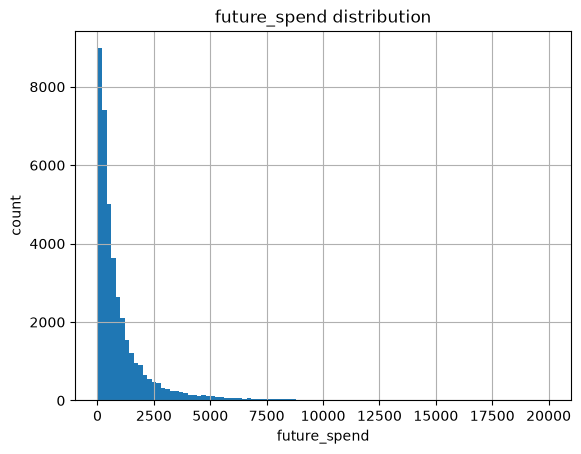

In [87]:
#Target Distribution

data['future_spend'].hist(bins=100)
plt.title('future_spend distribution')
plt.xlabel('future_spend')
plt.ylabel('count')
plt.show()

### Train Test Split

In [88]:
# Separate Features and Targets

y = data['future_spend']
X = data.drop(columns = ['future_spend', 'customer_id'])

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (40000, 18)
y shape: (40000,)


In [89]:
# Train Test Split

from sklearn.model_selection import train_test_split

y_binned = pd.qcut(y, q=100, duplicates='drop')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=617, stratify=y_binned)

print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Train mean spend:', y_train.mean())
print('Test mean spend:', y_test.mean())

Train: (28000, 18) Test: (12000, 18)
Train mean spend: 1108.3587028571428
Test mean spend: 1109.4146933333332


### Data Preprocessing

In [90]:
# Missing values
income_median = X_train['income'].median()
return_median = X_train['return_rate'].median()
print('income median:', income_median)
print('return_rate median:', return_median)

for df in [X_train, X_test, scoring_data]:
    # Flag which rows were missing
    df['income_missing'] = df['income'].isna().astype(int)
    df['return_rate_missing'] = df['return_rate'].isna().astype(int)
    # Fill numeric columns with the train median
    df['income'] = df['income'].fillna(income_median)
    df['return_rate'] = df['return_rate'].fillna(return_median)
    # Fill the text column with its own label
    df['device_type'] = df['device_type'].fillna('Unknown')

print('\nMissing left in X_train:', X_train.isna().sum().sum())
print('Missing left in X_test:', X_test.isna().sum().sum())
print('Missing left in scoring:', scoring_data.isna().sum().sum())

income median: 68000.0
return_rate median: 0.051

Missing left in X_train: 0
Missing left in X_test: 0
Missing left in scoring: 0


In [91]:
# Categorical Encoding

cat_cols = ['gender', 'region', 'preferred_category', 'device_type',
            'membership_program', 'newsletter_subscriber']

scoring_ids = scoring_data['customer_id']
scoring_X = scoring_data.drop(columns='customer_id')


X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)\
           .reindex(columns=X_train.columns, fill_value=0)
scoring_X = pd.get_dummies(scoring_X, columns=cat_cols, drop_first=True, dtype=int)\
              .reindex(columns=X_train.columns, fill_value=0)


print('\nNew columns:')
print([c for c in X_train.columns if any(c.startswith(k) for k in cat_cols)])


New columns:
['gender_Male', 'gender_Non-binary', 'region_Northeast', 'region_South', 'region_West', 'preferred_category_Beauty', 'preferred_category_Electronics', 'preferred_category_Home', 'preferred_category_Sports', 'device_type_Mobile', 'device_type_Tablet', 'device_type_Unknown', 'membership_program_Gold', 'membership_program_Platinum', 'membership_program_Silver', 'newsletter_subscriber_Yes']


### Linear Regression

In [94]:
# Fit and Evaluate
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import root_mean_squared_error, r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)

pred_train = lr.predict(X_train)
pred_test = lr.predict(X_test)

cv_rmse = -cross_val_score(LinearRegression(), X_train, y_train,
                           cv=5, scoring='neg_root_mean_squared_error').mean()

print('Train RMSE:', root_mean_squared_error(y_train, pred_train))
print('CV RMSE:   ', cv_rmse)
print('Test RMSE: ', root_mean_squared_error(y_test, pred_test))
print('Train R2:  ', r2_score(y_train, pred_train))
print('Test R2:   ', r2_score(y_test, pred_test))
print('Negative predictions in test:', (pred_test < 0).sum())


Train RMSE: 1183.3863821614368
CV RMSE:    1184.8197781659912
Test RMSE:  1194.797958919543
Train R2:   0.5182190334609825
Test R2:    0.5150708728412721
Negative predictions in test: 1706


In [96]:
# Coefficients

coefs = pd.Series(lr.coef_, index=X_train.columns).sort_values()
print('Intercept:', lr.intercept_)
print(coefs)

Intercept: -1611.6326180111423
return_rate                      -1456.383596
device_type_Mobile                -209.626241
membership_program_Silver         -198.701499
device_type_Tablet                -137.788688
promo_code_usage                  -134.515390
device_type_Unknown               -134.497097
membership_program_Gold           -109.799662
preferred_category_Sports          -58.940362
support_tickets                    -51.533823
preferred_category_Beauty          -44.776331
avg_session_duration               -14.708702
newsletter_subscriber_Yes           -9.984845
recency_days                        -7.850498
age                                 -4.227259
income                               0.007755
tenure_months                        1.272406
preferred_category_Home              3.591276
gender_Male                          8.610901
region_West                         12.184032
preferred_category_Electronics      17.709436
gender_Non-binary                   27.078148
ave